<h1><center>TASK 1</h1>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

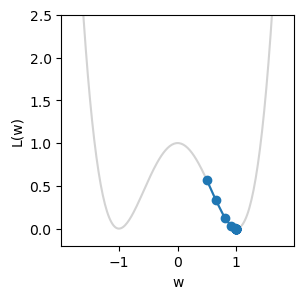

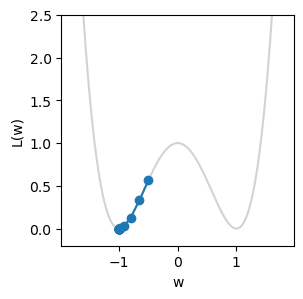

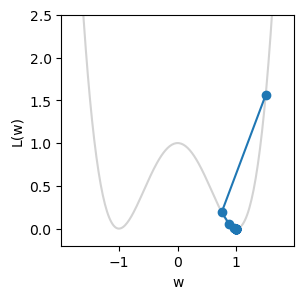

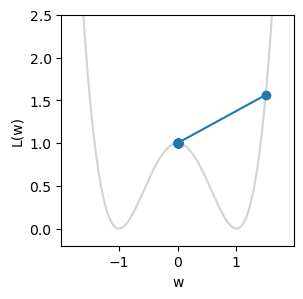

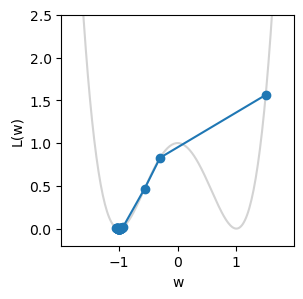

In [7]:
def L(w):
    return (w**2 - 1)**2

def g(w):
    return 4 * w**3 - 4 * w

def update(w, n):
    grad = g(w)
    return w - n * grad

w_list = [0.5, -0.5, 1.5, 1.5, 1.5]
lr_list = [0.1, 0.1, 0.1, 0.2, 0.24]

for i in range(len(w_list)):
    w = w_list[i]
    n = lr_list[i]
    
    points = [w]
    for step in range(30):
        w = update(w, n)
        points.append(w)

    w_grid = np.linspace(-1.8, 1.8, 200)
    plt.figure(figsize=(3,3))
    plt.plot(w_grid, (w_grid**2 - 1)**2, color="lightgray")
    plt.plot(points, (np.array(points)**2 - 1)**2, "o-")
    plt.ylim(-0.2, 2.5)
    plt.xlabel("w")
    plt.ylabel("L(w)")    
    plt.show()
    

<br>1 run it starts and finishes in the right valley
<br>2 run it starts and finishes in the left valley
<br>3 runs over the right bump
<br>4 runs over the bump and skips the right valley
<br>5 run it starts in the left valley, goes over the bump, and skips the right valley

<h1><center>TASK 2</center></h1>

gradient = (4, 20)
next point = (1.8, 0.0)


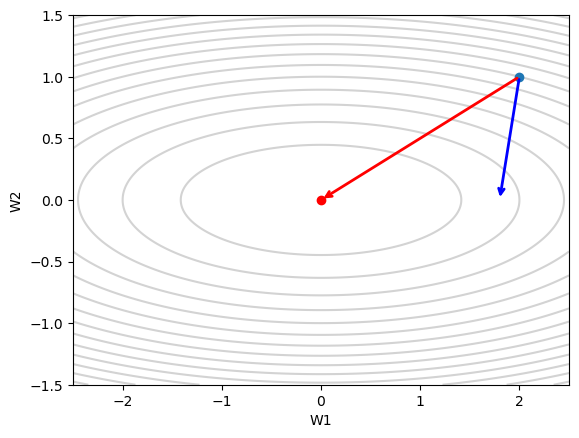

In [16]:
w1, w2 = np.meshgrid(
    np.linspace(-2.5, 2.5, 200), 
    np.linspace(-1.5, 1.5, 200))

start = (2,1)
minimum = (0,0)

plt.contour(w1, w2, w1**2 + 10 * w2**2, levels=15, colors="lightgray")

# plt.plot(path[:, 0], path[:, 1], "o-", markersize=3) # path has shape (31, 2)

plt.xlim(-2.5, 2.5); 
plt.ylim(-1.5, 1.5); 
plt.xlabel('W1')
plt.ylabel('W2')

n = 0.05
g = (2 * start[0], 20 * start[1])
gd_next = (
    start[0] - n * g[0],
    start[1] - n * g[1])
print("gradient =", g)
print("next point =", gd_next)
assert np.allclose(gd_next, (1.8, 0))


plt.annotate(
    '',
    xy=gd_next,
    xytext=start,
    arrowprops={"arrowstyle": "->", "color": "blue", "lw": 2}
)

plt.annotate(
    '',
    xy=minimum,
    xytext=start,
    arrowprops={"arrowstyle": "->", "color": "red", "lw": 2}
)
plt.plot(start[0], start[1], "o", markersize=6) # Start ooint
plt.plot(minimum[0], minimum[1], "o", color='red', markersize=6) # minimum
plt.show()



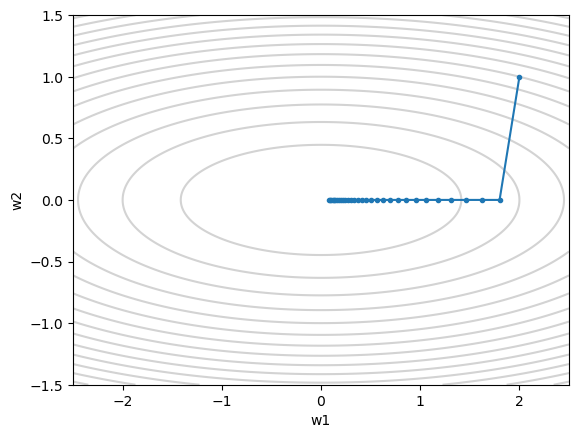

In [17]:
point = np.array(start, dtype=float)
path = [point.copy()]

n = 0.05
g = (2 * point[0], 20 * point[1])

for i in range(30):
    g = np.array([2 * point[0], 20 * point[1]])
    point = point - n * g
    path.append(point.copy())


path = np.array(path)
path.shape

plt.contour(w1, w2, w1**2 + 10 * w2**2,
            levels=15, colors="lightgray")
plt.plot(path[:, 0], path[:, 1], "o-", markersize=3)
plt.xlim(-2.5, 2.5)
plt.ylim(-1.5, 1.5)
plt.xlabel("w1")
plt.ylabel("w2")
plt.show()

In [19]:
def draw(n, start):
    point = np.array(start, dtype=float)
    path = [point.copy()]

    for i in range(30):
        g = np.array([2*point[0], 20 * point[1]])
        point = point - n * g
        path.append(point.copy())
    path = np.array(path)


    # plt.figure(figsize=(4,4))
    # plt.contour(w1, w2, w1**2 + 10 * w2**2,
    #         levels=15, colors="lightgray")
    # plt.plot(path[:, 0], path[:, 1], "o-", markersize=3)
    # plt.xlim(-2.5, 2.5)
    # plt.ylim(-1.5, 1.5)
    # plt.xlabel("w1")
    # plt.ylabel("w2")
    # plt.show()


    # print(path.shape)

    return path

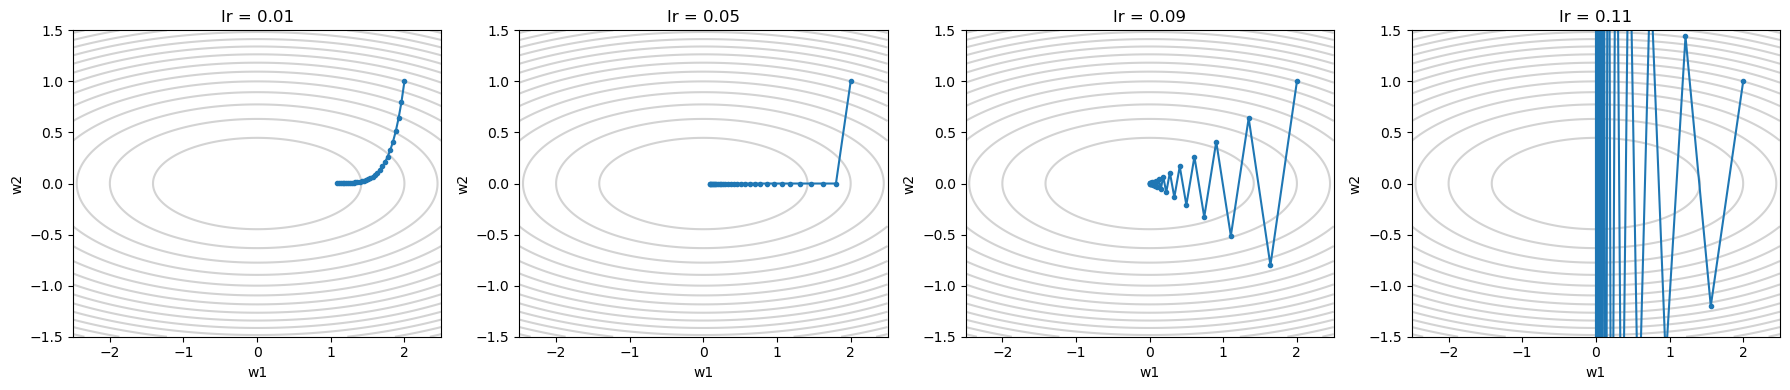

In [20]:
n = [0.01, 0.05, 0.09, 0.11]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, lr in zip(axes, n):
    path = draw(lr, start)

    ax.contour(w1, w2, w1**2 + 10 * w2**2,
               levels=15, colors="lightgray")

    ax.plot(path[:, 0], path[:, 1], "o-", markersize=3)

    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_title(f"lr = {lr}")
    ax.set_xlabel("w1")
    ax.set_ylabel("w2")

plt.tight_layout()
plt.show()

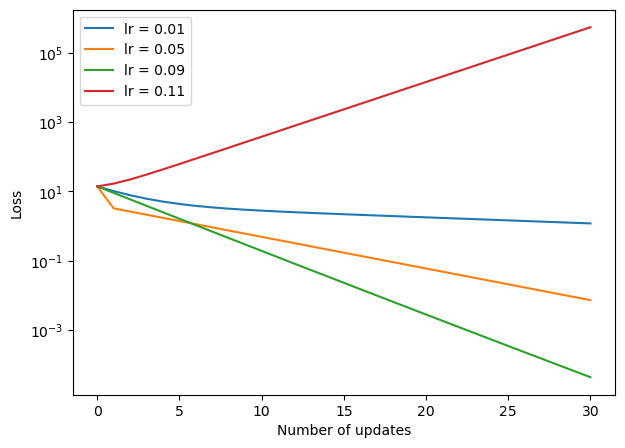

In [21]:
plt.figure(figsize=(7, 5))

for lr in n:
    path = draw(lr, start)
    losses = path[:,0]**2 + 10 * (path[:,1] ** 2)
    plt.plot(range(len(losses)), losses, label=f"lr = {lr}")

plt.yscale("log")
plt.xlabel("Number of updates")
plt.ylabel("Loss")
plt.legend()
plt.show()

<h1><center>TASK 3

In [22]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([1., 3., 5., 7., 9.])
w = 0
b = 0

def mse(w, b, x, y):
    yhat = w * x + b
    return np.mean((yhat - y) ** 2)


def gradients(w, b, x, y):
    yhat = w * x + b
    grad_w = np.mean((yhat - y) * x) * 2
    grad_b =  np.mean(yhat - y) * 2


    return grad_w, grad_b

    

def gd(lr, n_updates):
    
    w,b = 0, 0
    path = [[w,b]]
    history = [mse(w,b, x, y)]

    for i in range(n_updates):

        grad_w, grad_b = gradients(w, b, x, y)

        w = w - lr * grad_w
        b = b - lr * grad_b

        path.append((w, b))
        history.append(mse(w,b,x,y))

    return np.array(path), np.array(history)
    
print(mse(0, 0, x, y))        
print(gradients(0, 0, x, y))  


33.0
(np.float64(-28.0), np.float64(-10.0))


In [23]:
path, history = gd(0.05, 100)

print(path.shape, history.shape)
print(path[0], path[1])
print(history[0], history[1])

assert path.shape == (101, 2)
assert history.shape == (101,)
assert np.allclose(path[1], [1.4, 0.5])
assert np.isclose(history[0], 33)
assert np.isclose(history[1], 3.61)

(101, 2) (101,)
[0. 0.] [1.4 0.5]
33.0 3.6099999999999985


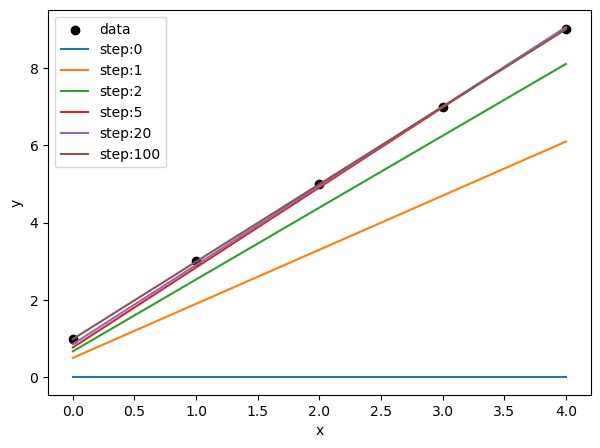

In [24]:
plt.figure(figsize=(7, 5))
plt.scatter(x, y, color="black", label="data")

for step in [0, 1, 2, 5, 20, 100]:
    w, b = path[step]


   
    yhat = w*x + b
    plt.plot(x, yhat,label=f'step:{step}')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

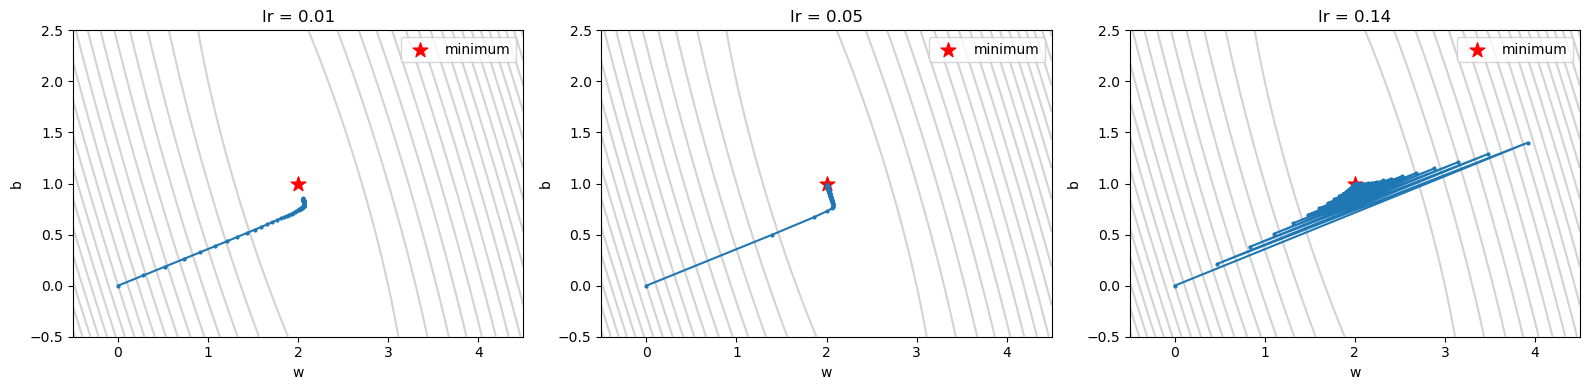

In [25]:
W, B = np.meshgrid(
    np.linspace(-0.5, 4.5, 200),
    np.linspace(-0.5, 2.5, 200)
)


Z = np.zeros_like(W)
for xi, yi in zip(x, y):
    Z += (W * xi + B - yi) ** 2
Z /= len(x)


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, lr in zip(axes, [0.01, 0.05, 0.14]):
    path, history = gd(lr, 100)

    ax.contour(W, B, Z, levels=20, colors="lightgray")
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=2)
    ax.scatter(2, 1, color="red", marker="*", s=120, label="minimum")

    ax.set_xlim(-0.5, 4.5)
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlabel("w")
    ax.set_ylabel("b")
    ax.set_title(f"lr = {lr}")
    ax.legend()

plt.tight_layout()
plt.show()

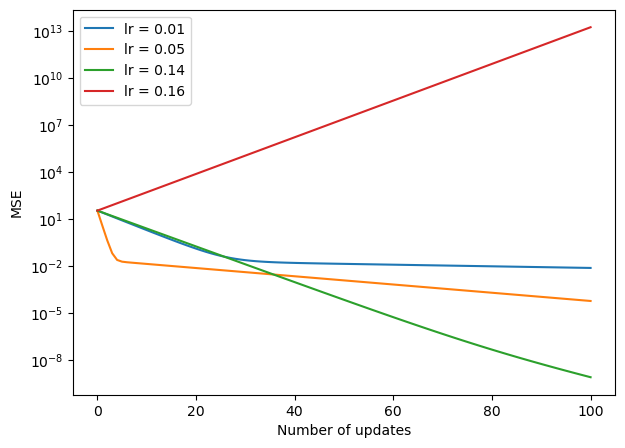

In [26]:
plt.figure(figsize=(7, 5))

for lr in [0.01, 0.05, 0.14, 0.16]:
    path, history = gd(lr, 100)
    plt.plot(range(len(history)), history, label=f"lr = {lr}")

plt.yscale("log")
plt.xlabel("Number of updates")
plt.ylabel("MSE")
plt.legend()
plt.show()